In [3]:
# Cell 1: load the three runs
from pathlib import Path
import pandas as pd

ROOT = Path("..")  # e.g. Path(r"C:\Users\PUSHKAR\Desktop\election-dynamics-simulator")
runs = {name: ROOT / "results" / f"{name}_seed42" for name in ("social", "ordinary", "smear")}

summary = {n: pd.read_csv(p / "daily_summary.csv").set_index("day") for n, p in runs.items()}
support = {n: pd.read_csv(p / "daily_support.csv").pivot(index="day", columns="candidate_id", values="mean_support")
           for n, p in runs.items()}
final = {n: pd.read_csv(p / "final_state.csv") for n, p in runs.items()}

In [4]:
# Cell 2: did the campaign fire, and did opinions move?
# Expect 1 action and 750 exposures on days 10-15, 0 otherwise.
# Expect ordinary opinion_mean to shift from day 10; smear should equal social.
days = [9, 10, 15, 16, 30]
for name in runs:
    print(name)
    display(summary[name].loc[days, ["opinion_mean", "active_campaign_actions", "campaign_exposures_today"]])

social


,opinion_mean,active_campaign_actions,campaign_exposures_today
day,,,
9,-0.049502,0,0
10,-0.050139,0,0
15,-0.053198,0,0
16,-0.053651,0,0
30,-0.057832,0,0


ordinary


,opinion_mean,active_campaign_actions,campaign_exposures_today
day,,,
9,-0.049502,0,0
10,-0.055344,1,750
15,-0.080409,1,750
16,-0.080770,0,0
30,-0.080080,0,0


smear


,opinion_mean,active_campaign_actions,campaign_exposures_today
day,,,
9,-0.049502,0,0
10,-0.050139,1,750
15,-0.053198,1,750
16,-0.053651,0,0
30,-0.057832,0,0


In [5]:
# Cell 3: support by candidate.
# Expect all three to match up to day 9, then CAND_0003 lower and CAND_0001 higher in both campaigns.
pd.concat({name: support[name].loc[[9, 15, 30]] for name in runs}, axis=1).round(4)

social                      ordinary                      \
candidate_id CAND_0001 CAND_0002 CAND_0003 CAND_0001 CAND_0002 CAND_0003   
day                                                                        
9               0.6530    0.0643    0.2827    0.6530    0.0643    0.2827   
15              0.6581    0.0669    0.2750    0.6690    0.0674    0.2636   
30              0.6660    0.0721    0.2619    0.6754    0.0724    0.2522   

                 smear                      
candidate_id CAND_0001 CAND_0002 CAND_0003  
day                                         
9               0.6530    0.0643    0.2827  
15              0.6677    0.0681    0.2642  
30              0.6755    0.0733    0.2512

In [6]:
# Cell 4: per-voter checks
social, ordinary, smear = final["social"], final["ordinary"], final["smear"]
print("smear: opinions identical to social? ", (smear.final_opinion == social.final_opinion).all())         # True
print("smear: voters with lower CAND_0003 support:", (smear.support_CAND_0003 < social.support_CAND_0003).sum())  # 750
print("ordinary: voters whose opinion changed:", (ordinary.final_opinion != social.final_opinion).sum())   # ~2846

smear: opinions identical to social?  True
smear: voters with lower CAND_0003 support: 750
ordinary: voters whose opinion changed: 2846


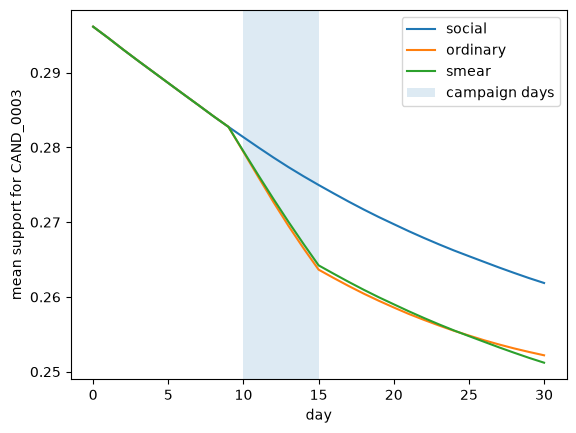

In [7]:
# Cell 5 (optional): plot CAND_0003 support over time
import matplotlib.pyplot as plt
for name in runs:
    plt.plot(support[name].index, support[name]["CAND_0003"], label=name)
plt.axvspan(10, 15, alpha=0.15, label="campaign days")
plt.xlabel("day"); plt.ylabel("mean support for CAND_0003"); plt.legend(); plt.show()